# Storytelling with Dashboards

A **dashboard** is a page of charts and numbers that people check regularly to monitor and decide. Unlike a storyboard (Lesson 06), it is not read once from start to end: it must answer the most important questions at a glance and allow a second, deeper look.

**After this lesson you can:**

1. Define the audience, decisions and KPIs of a dashboard.
2. Design KPI tiles with comparison and context.
3. Lay out a dashboard by priority (top-left first, overview to detail).
4. Build a static executive dashboard and review it.

**Data:** NYC yellow taxi trips, January and February 2024 (February is "this month", January the comparison).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

jan, feb = load_month("2024-01"), load_month("2024-02")
names = zones.set_index("LocationID")["Zone"]
boroughs = zones.set_index("LocationID")["Borough"]

## 1. Audience, Decisions, KPIs

| Audience | Decision | KPI |
| :--- | :--- | :--- |
| fleet operations manager | how many drivers per day and hour | trips per day, trips per hour profile |
| finance | is revenue on track | revenue per day, average fare |
| customer experience | are passengers satisfied | tip rate on card trips (proxy) |

A KPI needs: a **definition** (formula and filters), a **comparison** (previous period, target), and a **direction** (is up good?). Comparing months of different length (29 vs 31 days) needs **per-day** values.

In [2]:
def kpis(df: pd.DataFrame, days: int) -> dict:
    card = df[df["payment_type"] == 1]
    return {
        "Trips per day": len(df) / days,
        "Revenue per day (USD)": df["total_amount"].sum() / days,
        "Average fare (USD)": df["fare_amount"].mean(),
        "Card tip rate (%)": 100 * card["tip_amount"].sum() / card["fare_amount"].sum(),
        "Median trip (min)": df["duration_min"].median(),
    }

now, prev = kpis(feb, 29), kpis(jan, 31)
table = pd.DataFrame({"February": now, "January": prev})
table["change_%"] = 100 * (table["February"] / table["January"] - 1)
table.round(2)

,February,January,change_%
Trips per day,99512.07,92121.58,8.02
Revenue per day (USD),2709744.42,2516338.45,7.69
Average fare (USD),18.40,18.46,-0.32
Card tip rate (%),22.62,22.64,-0.10
Median trip (min),12.10,11.75,2.98


## 2. Build the Dashboard

Layout principles:

- **Top row:** KPI tiles with the value, the change and an arrow coloured by direction (green = good for the business).
- **Middle:** the main trend (daily trips, both months aligned by day of month).
- **Bottom:** the breakdowns that explain the trend (by hour, by zone).
- Titles state what the reader should notice; footers give definitions and data sources.

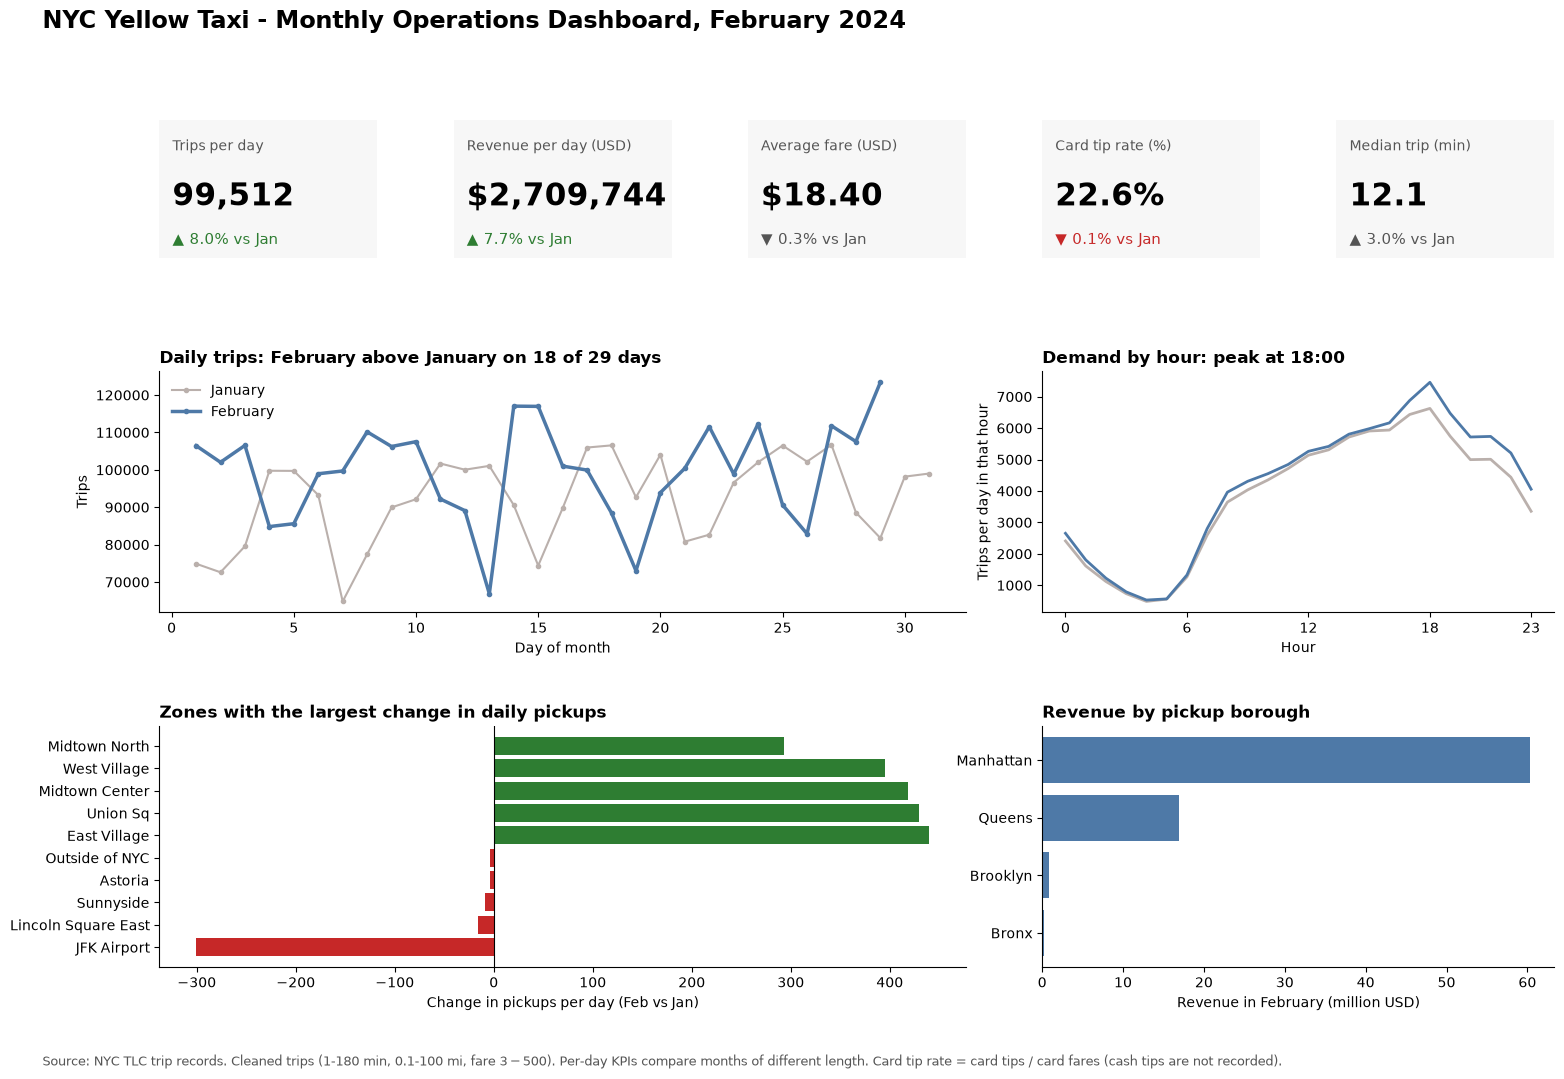

In [3]:
GOOD, BAD, NEUTRAL, ACCENT, CONTEXT = "#2E7D32", "#C62828", "#555555", "#4E79A7", "#BAB0AC"
good_direction = {"Trips per day": 1, "Revenue per day (USD)": 1, "Average fare (USD)": 0, "Card tip rate (%)": 1, "Median trip (min)": 0}
fmt = {"Trips per day": "{:,.0f}", "Revenue per day (USD)": "${:,.0f}", "Average fare (USD)": "${:.2f}",
       "Card tip rate (%)": "{:.1f}%", "Median trip (min)": "{:.1f}"}

fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(3, 5, height_ratios=[0.8, 1.4, 1.4], hspace=0.55, wspace=0.35)
for i, (name, row) in enumerate(table.iterrows()):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ch = row["change_%"]
    color = NEUTRAL if good_direction[name] == 0 else (GOOD if ch * good_direction[name] > 0 else BAD)
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#F7F7F7", zorder=0))
    ax.text(0.06, 0.78, name, fontsize=10, color=NEUTRAL, transform=ax.transAxes)
    ax.text(0.06, 0.38, fmt[name].format(row["February"]), fontsize=22, fontweight="bold", transform=ax.transAxes)
    ax.text(0.06, 0.1, f"{'▲' if ch > 0 else '▼'} {abs(ch):.1f}% vs Jan", fontsize=11, color=color, transform=ax.transAxes)

ax = fig.add_subplot(gs[1, :3])
dj = jan.groupby(jan["tpep_pickup_datetime"].dt.day).size()
dfb = feb.groupby(feb["tpep_pickup_datetime"].dt.day).size()
for d, label, color, lw in [(dj, "January", CONTEXT, 1.5), (dfb, "February", ACCENT, 2.5)]:
    ax.plot(d.index, d.values, color=color, lw=lw, label=label, marker="o", ms=3)
above = (dfb > dj.reindex(dfb.index)).sum()
ax.set(xlabel="Day of month", ylabel="Trips")
ax.set_title(f"Daily trips: February above January on {above} of {len(dfb)} days", loc="left", fontweight="bold")
ax.legend(frameon=False)

ax = fig.add_subplot(gs[1, 3:])
for df, label, color, days in [(jan, "January", CONTEXT, 31), (feb, "February", ACCENT, 29)]:
    h = df.groupby(df["tpep_pickup_datetime"].dt.hour).size() / days
    ax.plot(h.index, h.values, color=color, lw=2, label=label)
ax.set(xlabel="Hour", ylabel="Trips per day in that hour", xticks=[0, 6, 12, 18, 23])
ax.set_title(f"Demand by hour: peak at {h.idxmax()}:00", loc="left", fontweight="bold")

ax = fig.add_subplot(gs[2, :3])
zj = jan.groupby("PULocationID").size() / 31
zf = feb.groupby("PULocationID").size() / 29
delta = (zf - zj).dropna()
top = pd.concat([delta.nsmallest(5), delta.nlargest(5)])
ax.barh([names.get(z, z) for z in top.index], top.values, color=[BAD if v < 0 else GOOD for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Change in pickups per day (Feb vs Jan)")
ax.set_title("Zones with the largest change in daily pickups", loc="left", fontweight="bold")

ax = fig.add_subplot(gs[2, 3:])
b = feb.assign(b=feb["PULocationID"].map(boroughs)).groupby("b")["total_amount"].sum().sort_values()
b = b[b.index.isin(["Manhattan", "Queens", "Brooklyn", "Bronx"])]
ax.barh(b.index, b.values / 1e6, color=ACCENT)
ax.set(xlabel="Revenue in February (million USD)")
ax.set_title("Revenue by pickup borough", loc="left", fontweight="bold")

fig.suptitle("NYC Yellow Taxi - Monthly Operations Dashboard, February 2024", x=0.06, ha="left", fontsize=17, fontweight="bold")
fig.text(0.06, 0.02, "Source: NYC TLC trip records. Cleaned trips (1-180 min, 0.1-100 mi, fare $3-$500). Per-day KPIs compare months "
         "of different length. Card tip rate = card tips / card fares (cash tips are not recorded).", fontsize=9, color=NEUTRAL)
plt.show()

## 3. Review the Dashboard

| Principle | Check in this dashboard |
| :--- | :--- |
| the most important numbers first | KPI tiles in the top row |
| every number has a comparison | change vs January on each tile |
| colour has meaning | green/red only for good/bad changes; blue = this month, grey = comparison |
| titles carry the message | "February ran above January on most days" instead of "Daily trips" |
| definitions are visible | footer with filters and KPI formulas |
| no chart junk | no 3-D, no gauges, no decorative images |

**Gauges and speedometers** use a lot of space to show one number with poor precision; a KPI tile with a sparkline or a bullet chart says more in less space.

*Insight: Design a dashboard backwards from decisions: which questions must be answered at a glance, which KPIs answer them, what each KPI is compared with, and only then which charts to use. Put definitions on the page, not in someone's head.*

## Real-World Use Case or Analogy

A dashboard is like the **instrument panel of a car**: the speed is large and central, warning lights appear only when something needs attention, and details (fuel consumption history) are one click away. Nobody would design a car where the speedometer is a pie chart.

Operations teams in logistics, ride-hailing and retail check dashboards like this every morning. Lessons 10–14 build interactive versions in Tableau, Power BI and Apache Superset.